# DSK807 Applied Machine Learning Final Project
## Customer Churn Prediction in a Subscription-Based Service

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, recall_score, f1_score, fbeta_score, make_scorer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import regularizers
import tensorflow as tf
import shap
import numpy as np

In [ ]:
# Load data
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [3]:
# Drop ID columns
df_noID = df.drop(["customerID"], axis=1)
df_noID

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [4]:
# Convert TotalCharges column from object to numeric. It was considered object because blank spaces were used for missing values.
df_noID['TotalCharges'] = pd.to_numeric(
    df_noID['TotalCharges'],
    errors='coerce'
)
df_noID

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [5]:
# Split data
X = df_noID.iloc[:, 0:19].copy()
y = df_noID.iloc[:, -1].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,shuffle=True, stratify=y, random_state=42)

In [6]:
# Impute missing values of TotalCharges column
imputer = SimpleImputer(strategy='median')

X_train[['TotalCharges']] = imputer.fit_transform(
    X_train[['TotalCharges']]
)

X_test[['TotalCharges']] = imputer.transform(
    X_test[['TotalCharges']]
)

## Feature Engineering

In [7]:
''''
# New / Long-Term Customer Tenure Flag

X_train['is_new_customer'] = (X_train['tenure'] <= 6).astype(int)
X_test['is_new_customer'] = (X_test['tenure'] <= 6).astype(int)

X_train['is_long_term'] = (X_train['tenure'] >= 36).astype(int)
X_test['is_long_term'] = (X_test['tenure'] >= 36).astype(int)


# Month-to-Month Contract Flag

X_train['is_monthly_contract'] = (
    X_train['Contract'] == 'Month-to-month'
).astype(int)

X_test['is_monthly_contract'] = (
    X_test['Contract'] == 'Month-to-month'
).astype(int)


contract_mapping = {
    'Month-to-month': 0,
    'One year': 1,
    'Two year': 2
}

X_train['contract_numeric'] = X_train['Contract'].map(contract_mapping)
X_test['contract_numeric'] = X_test['Contract'].map(contract_mapping)

X_train['tenure_contract_interaction'] = (
    X_train['tenure'] * X_train['contract_numeric']
)
X_test['tenure_contract_interaction'] = (
    X_test['tenure'] * X_test['contract_numeric']
)
'''

"'\n# New / Long-Term Customer Tenure Flag\n\nX_train['is_new_customer'] = (X_train['tenure'] <= 6).astype(int)\nX_test['is_new_customer'] = (X_test['tenure'] <= 6).astype(int)\n\nX_train['is_long_term'] = (X_train['tenure'] >= 36).astype(int)\nX_test['is_long_term'] = (X_test['tenure'] >= 36).astype(int)\n\n\n# Month-to-Month Contract Flag\n\nX_train['is_monthly_contract'] = (\n    X_train['Contract'] == 'Month-to-month'\n).astype(int)\n\nX_test['is_monthly_contract'] = (\n    X_test['Contract'] == 'Month-to-month'\n).astype(int)\n\n\ncontract_mapping = {\n    'Month-to-month': 0,\n    'One year': 1,\n    'Two year': 2\n}\n\nX_train['contract_numeric'] = X_train['Contract'].map(contract_mapping)\nX_test['contract_numeric'] = X_test['Contract'].map(contract_mapping)\n\nX_train['tenure_contract_interaction'] = (\n    X_train['tenure'] * X_train['contract_numeric']\n)\nX_test['tenure_contract_interaction'] = (\n    X_test['tenure'] * X_test['contract_numeric']\n)\n"

### One Hot Encoding/Scaling

In [8]:
# Identify categorical & numerical columns
categorical_cols = X_train.select_dtypes(include="object").columns
numerical_cols = X_train.select_dtypes(exclude="object").columns

In [9]:
# Remove SeniorCitizen from numerical columns (if not already removed)
numerical_cols = [col for col in numerical_cols if col != 'SeniorCitizen']

# Remove is_new_customer from numerical columns (if not already removed)
#numerical_cols = [col for col in numerical_cols if col != 'is_new_customer']

# Remove is_long_term from numerical columns (if not already removed)
#numerical_cols = [col for col in numerical_cols if col != 'is_long_term']

# Remove is_monthly_contract from numerical columns (if not already removed)
#numerical_cols = [col for col in numerical_cols if col != 'is_monthly_contract']

# Add SeniorCitizen to categorical columns
categorical_cols = categorical_cols.append(
    pd.Index(['SeniorCitizen'])
)

# Add is_new_customer to categorical columns
#categorical_cols = categorical_cols.append(
#    pd.Index(['is_new_customer'])
#)

# Add is_long_term to categorical columns
#categorical_cols = categorical_cols.append(
#    pd.Index(['is_long_term'])
#)

# Add is_monthly_contract to categorical columns
#categorical_cols = categorical_cols.append(
#    pd.Index(['is_monthly_contract'])
#)

# Remove Contract from categorical columns
categorical_cols = categorical_cols.drop('Contract')

In [10]:
numerical_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

In [11]:
categorical_cols

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling',
       'PaymentMethod', 'SeniorCitizen'],
      dtype='object')

In [12]:
# Define ordinal encoder for Contract
contract_encoder = OrdinalEncoder(
    categories=[['Month-to-month', 'One year', 'Two year']]
)

# Perform One Hot Encoding and Scaling
preprocessor = ColumnTransformer(
    transformers=[
        ('contract', contract_encoder, ['Contract']),
        ('cat', OneHotEncoder(sparse_output=False, drop='if_binary'), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
X_train_processed.shape

(5634, 38)

In [13]:
# Convert string labels to numerical
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

In [14]:
# Prepare feature names for SHAP

# Ordinal feature
contract_feature = ['Contract']

# One-hot encoded categorical features
cat_features = preprocessor.named_transformers_['cat'] \
    .get_feature_names_out(categorical_cols)

# Numerical features
num_features = numerical_cols

# Final feature name list
feature_names = (
    contract_feature +
    list(cat_features) +
    list(num_features)
)

## Shallow Learners

### Logistic Regression Hyperparameter Tuning

In [ ]:
# Grid Search
grid_search = GridSearchCV(
    LogisticRegression(random_state=42, max_iter=1000),
    {
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2', 'elasticnet'],
        'solver': ['liblinear', 'lbfgs', 'saga']
    },
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train_processed, y_train)

y_pred = grid_search.predict(X_test_processed)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Best parameters: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
Best CV accuracy: 0.8076
Test accuracy: 0.8062


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
120 fits failed out of a total of 270.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py", line 1193, in fit
    solver = _check_solv

###Logistic Regression

Test accuracy: 0.7942
              precision    recall  f1-score   support

          No       0.84      0.89      0.86      1035
         Yes       0.64      0.52      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



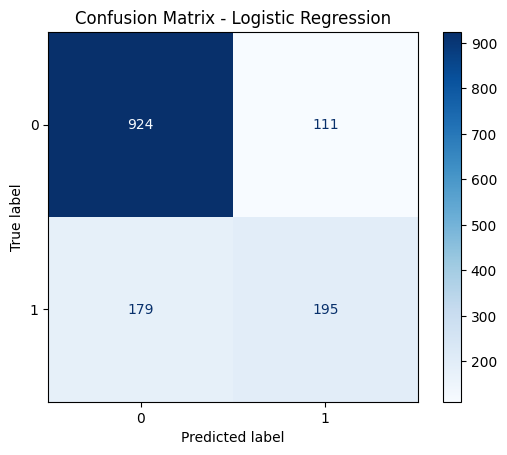

In [ ]:
log_reg = LogisticRegression(
    random_state=42,
    max_iter=1000,
    penalty='l1',
    C=0.1,
    solver='saga'
)

log_reg.fit(X_train_processed, y_train)

# Predictions
y_pred = log_reg.predict(X_test_processed)

# Accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

/tmp/ipython-input-488722418.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


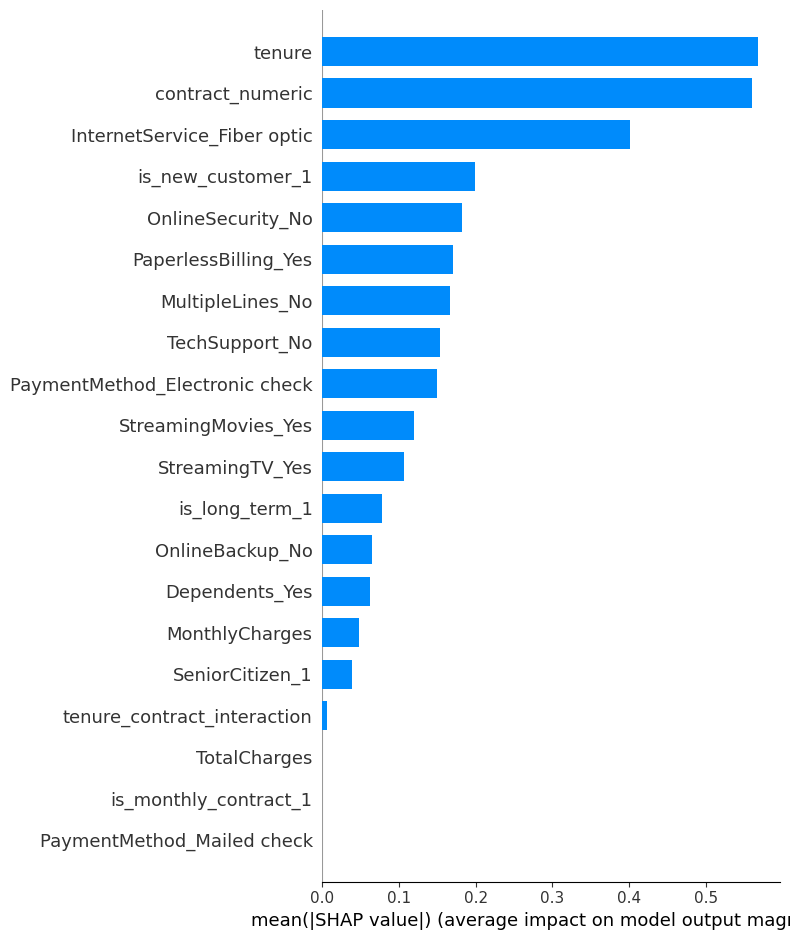

In [ ]:
# SHAP

explainer_lr = shap.LinearExplainer(log_reg, X_train_processed)

shap_values_lr = explainer_lr.shap_values(X_test_processed)

shap.summary_plot(
    shap_values_lr,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar"
)

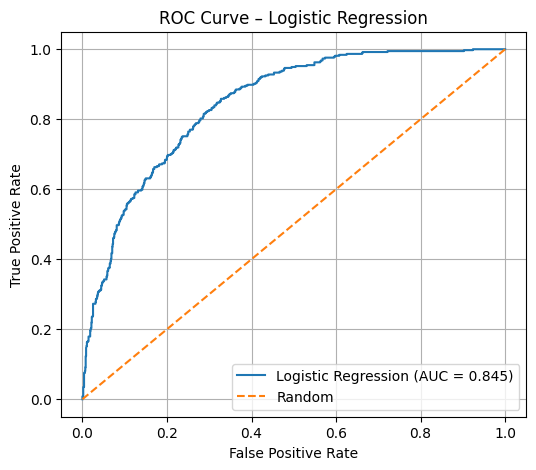

In [ ]:
# ROC Plot

# Predict probabilities
lr_probs = log_reg.predict_proba(X_test_processed)[:, 1]

# ROC + AUC
fpr_lr, tpr_lr, _ = roc_curve(y_test_encoded, lr_probs)
auc_lr = roc_auc_score(y_test_encoded, lr_probs)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()

### Random Forest Hyperparameter Tuning

In [ ]:
# Grid Search
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {'n_estimators': [100, 200, 500], 'max_depth': [10, 20, 30, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]},
    cv=5, scoring='accuracy'
)
grid_search.fit(X_train_processed, y_train)

y_pred = grid_search.predict(X_test_processed)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
Best CV accuracy: 0.8024
Test accuracy: 0.8034


### Random Forest

Test accuracy: 0.8077
              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.68      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



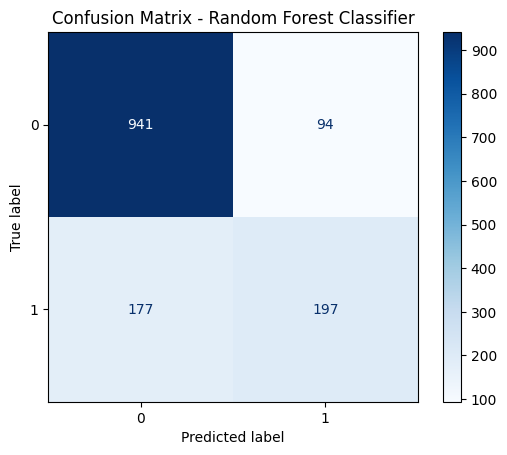

In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

rf.fit(X_train_processed, y_train)

# Predictions
y_pred = rf.predict(X_test_processed)

# Evaluation
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Random Forest Classifier")
plt.show()

/tmp/ipython-input-3935618092.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


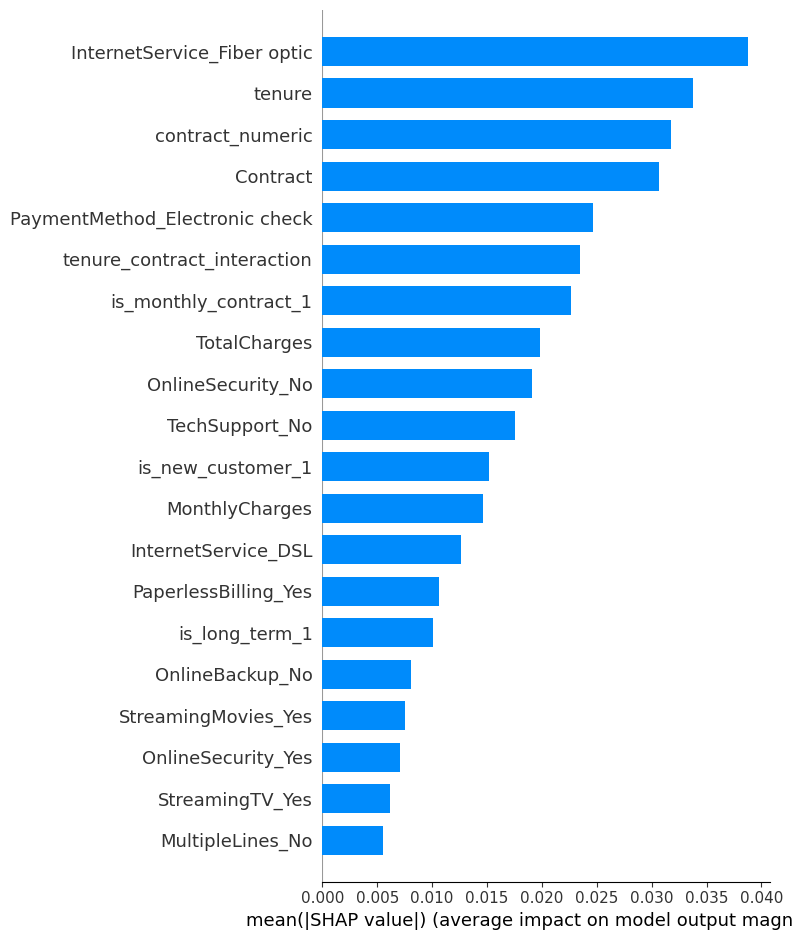

In [ ]:
#SHAP

explainer_rf = shap.TreeExplainer(rf)
shap_values_rf = explainer_rf.shap_values(X_test_processed)

if shap_values_rf.ndim == 3:
    shap_values_rf_churn = shap_values_rf[:, :, 1]
else:
    shap_values_rf_churn = shap_values_rf[1]

shap.summary_plot(
    shap_values_rf_churn,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar"
)

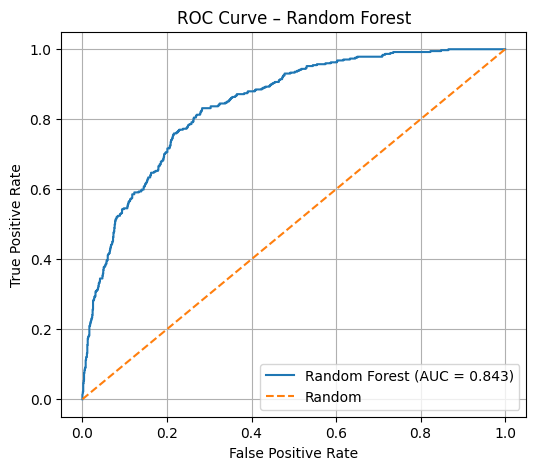

In [ ]:
# ROC Plot

# Predict probabilities
rf_probs = rf.predict_proba(X_test_processed)[:, 1]

# ROC + AUC
fpr_rf, tpr_rf, _ = roc_curve(y_test_encoded, rf_probs)
auc_rf = roc_auc_score(y_test_encoded, rf_probs)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Random Forest')
plt.legend()
plt.grid(True)
plt.show()

### Gradient Boosting Hyperparameter Tuning

In [ ]:
# Grid Search for XGBoost
grid_search = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss'),
    {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2, 0.25],
        'max_depth': [2, 3, 4, 5],
        'subsample': [0.8, 0.9, 1.0],
        'colsample_bytree': [0.8, 0.9, 1.0]
    },
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train_processed, y_train_encoded)

# Explicit prediction and accuracy calculation
y_pred_encoded = grid_search.predict(X_test_processed)
test_accuracy = accuracy_score(y_test_encoded, y_pred_encoded)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


KeyboardInterrupt: 

### Gradient Boosting

Test accuracy: 0.8077
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.67      0.54      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409

F2 score: 0.5642


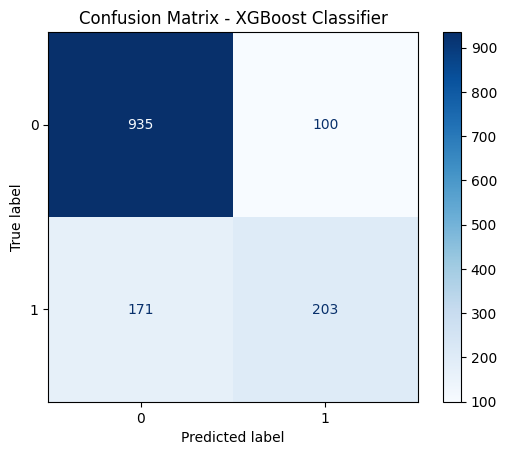

In [ ]:
xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    subsample=0.8,
    colsample_bytree=0.9,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train_processed, y_train_encoded)

# Explicit prediction and accuracy calculation
y_pred_encoded = xgb.predict(X_test_processed)
test_accuracy = accuracy_score(y_test_encoded, y_pred_encoded)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_test_encoded, y_pred_encoded))

f2 = fbeta_score(y_test_encoded, y_pred_encoded, beta=2, pos_label=1, average='binary')
print(f"F2 score: {f2:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test_encoded, y_pred_encoded)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - XGBoost Classifier")
plt.show()

/tmp/ipython-input-3309346482.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


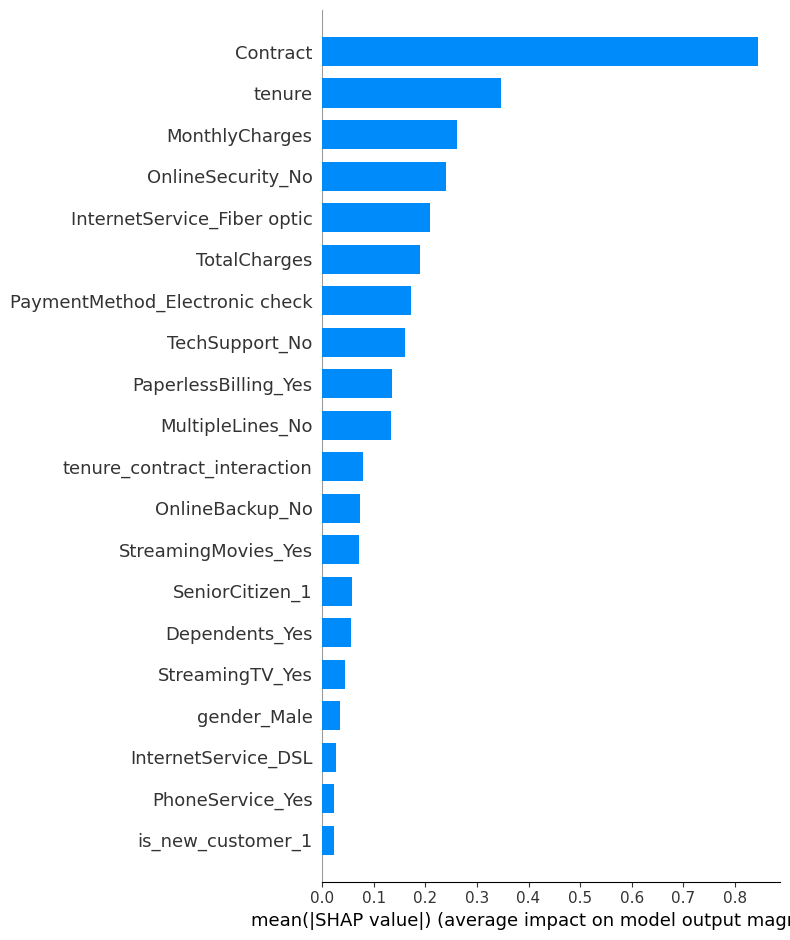

In [ ]:
# SHAP

explainer_xgb = shap.TreeExplainer(xgb)
shap_values_xgb = explainer_xgb.shap_values(X_test_processed)

shap.summary_plot(
    shap_values_xgb,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar"
)

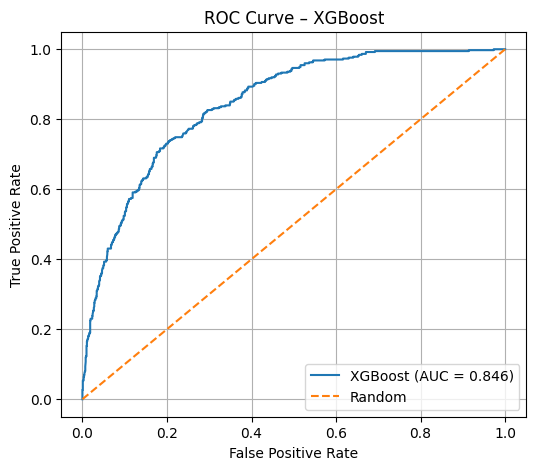

In [ ]:
# ROC Plot

# Predict probabilities
xgb_probs = xgb.predict_proba(X_test_processed)[:, 1]

# ROC + AUC
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_encoded, xgb_probs)
auc_xgb = roc_auc_score(y_test_encoded, xgb_probs)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – XGBoost')
plt.legend()
plt.grid(True)
plt.show()

### Ensemble Learner

Accuracy: 0.8034066713981547
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



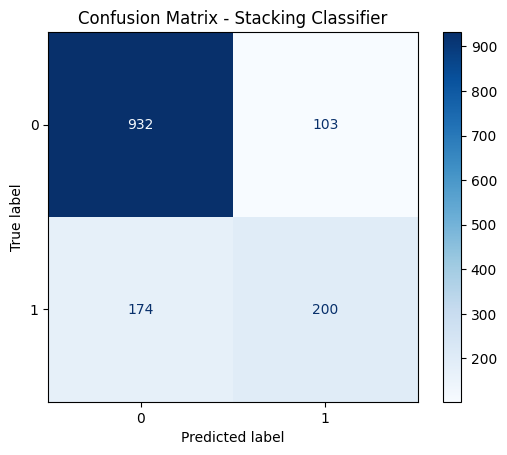

In [ ]:
# Base learners
base_learners = [
    ("lr", LogisticRegression(max_iter=1000, C= 100, penalty= 'l1', solver= 'liblinear', random_state=42)),
    ("rf", RandomForestClassifier(max_depth= 10, min_samples_leaf= 4, min_samples_split= 2, n_estimators= 500, random_state=42)),
    ("xgb", XGBClassifier(colsample_bytree= 1.0, learning_rate= 0.05, max_depth= 2, n_estimators= 200, subsample= 0.9, eval_metric='logloss', random_state=42))
]

# Meta Learner
meta_learner = LogisticRegression(max_iter=1000, C= 100, penalty= 'l1', solver= 'liblinear', random_state=42)

stacking_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

stacking_model.fit(X_train_processed, y_train)

y_pred = stacking_model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Stacking Classifier")
plt.show()

## Neural Network

In [15]:
# Training Settings
n_input = X_train_processed.shape[1]
n_output = 1 # number of classes
_activation = 'relu'
_epochs = 200
_batch_size = 32
_lr = 0.0002
optimizer = Adam(learning_rate=_lr)

# Add early stopping
early_stopping = EarlyStopping(
    monitor='val_accuracy',
    min_delta=0.0001, # minimium amount of change to count as an improvement
    patience=30, # how many epochs to wait before stopping
    restore_best_weights=True,
)


# Build model
model = Sequential([
    Input(shape=(n_input,)),      # Input layer

    Dense(64, activation=_activation),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation=_activation),
    BatchNormalization(),
    Dropout(0.3),

    Dense(16, activation=_activation),
    BatchNormalization(),
    Dropout(0.1),

    Dense(n_output, activation='sigmoid')        # Output layer
])

# Compile
model.compile(optimizer=optimizer,
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Train
history = model.fit(X_train_processed, y_train_encoded,
                    epochs=_epochs,
                    batch_size=_batch_size,
                    callbacks=[early_stopping],
                    validation_data=(X_test_processed, y_test_encoded))

# Evaluate
test_loss, test_acc = model.evaluate(X_test_processed, y_test_encoded)
print(f"Test accuracy: {test_acc:.3f}")

# Predict probabilities
y_pred_prob = model.predict(X_test_processed)

# Convert probabilities to class labels (0 or 1)
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(y_test_encoded, y_pred))

f2 = fbeta_score(y_test_encoded, y_pred, beta=2, pos_label=1, average='binary')
print(f"F2 score: {f2:.4f}")

cm = confusion_matrix(y_test_encoded, y_pred)
print("Confusion Matrix:")
print(cm)


Epoch 1/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5721 - loss: 0.7534 - val_accuracy: 0.7154 - val_loss: 0.6082
Epoch 2/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6652 - loss: 0.6280 - val_accuracy: 0.7402 - val_loss: 0.5538
Epoch 3/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7204 - loss: 0.5647 - val_accuracy: 0.7566 - val_loss: 0.5243
Epoch 4/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7307 - loss: 0.5498 - val_accuracy: 0.7587 - val_loss: 0.5071
Epoch 5/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7423 - loss: 0.5378 - val_accuracy: 0.7679 - val_loss: 0.4917
Epoch 6/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7591 - loss: 0.5168 - val_accuracy: 0.7743 - val_loss: 0.4797
Epoch 7/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7716 - loss: 0.4951 - val_accuracy: 0.7821 - val_loss: 0.4688
Epoch 8/200
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7715 - loss: 0.4809 - val_accu

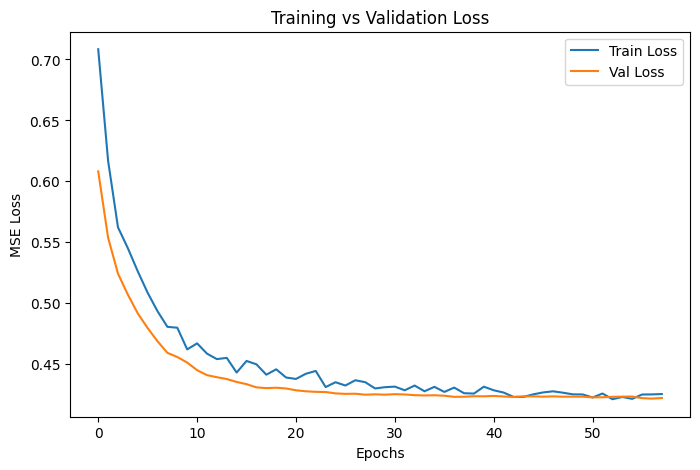

In [16]:
# --- Visualize Training ---
def plot_history(history):
  plt.figure(figsize=(8,5))
  plt.plot(history.history['loss'], label='Train Loss')
  plt.plot(history.history['val_loss'], label='Val Loss')
  plt.title("Training vs Validation Loss")
  plt.xlabel("Epochs")
  plt.ylabel("MSE Loss")
  plt.legend()
  plt.show()

plot_history(history)

In [17]:
X_test_processed.shape

(1409, 38)

/usr/local/lib/python3.12/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(100, 38))']
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(200, 38))']
  warnings.warn(msg)
/tmp/ipython-input-2290820232.py:75: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and 

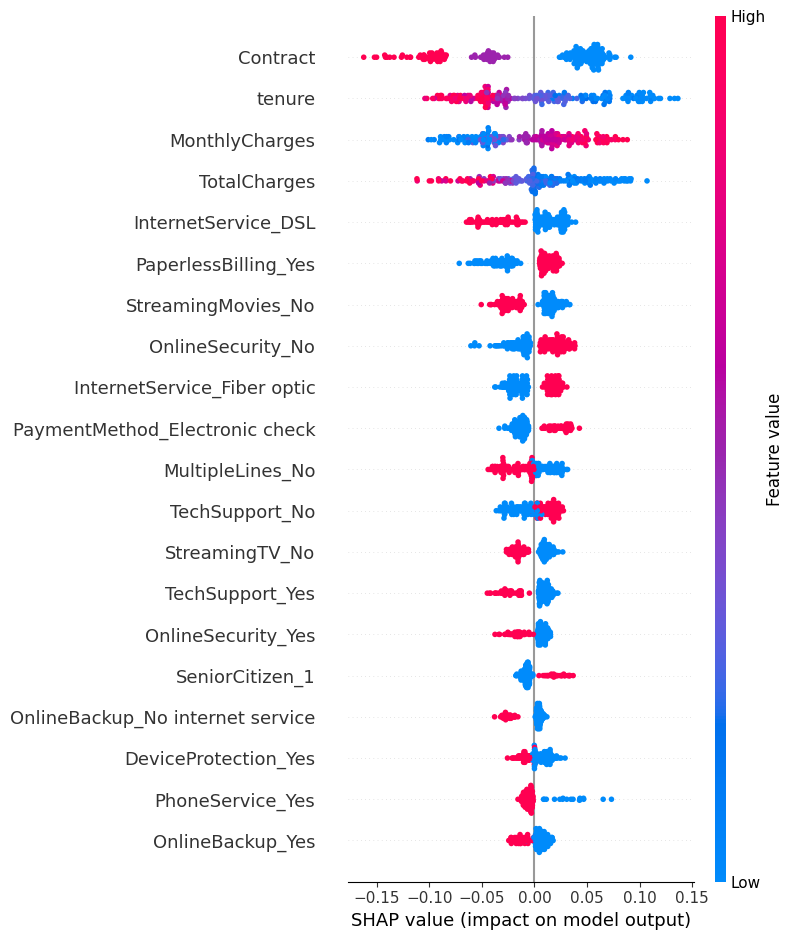

/tmp/ipython-input-2290820232.py:84: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


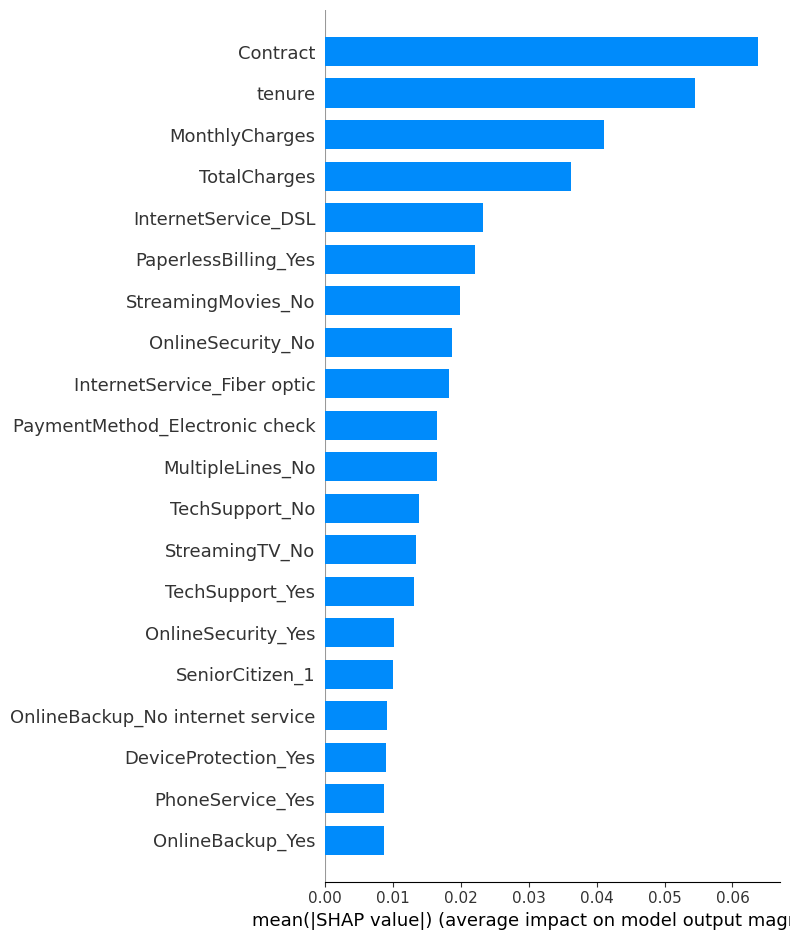

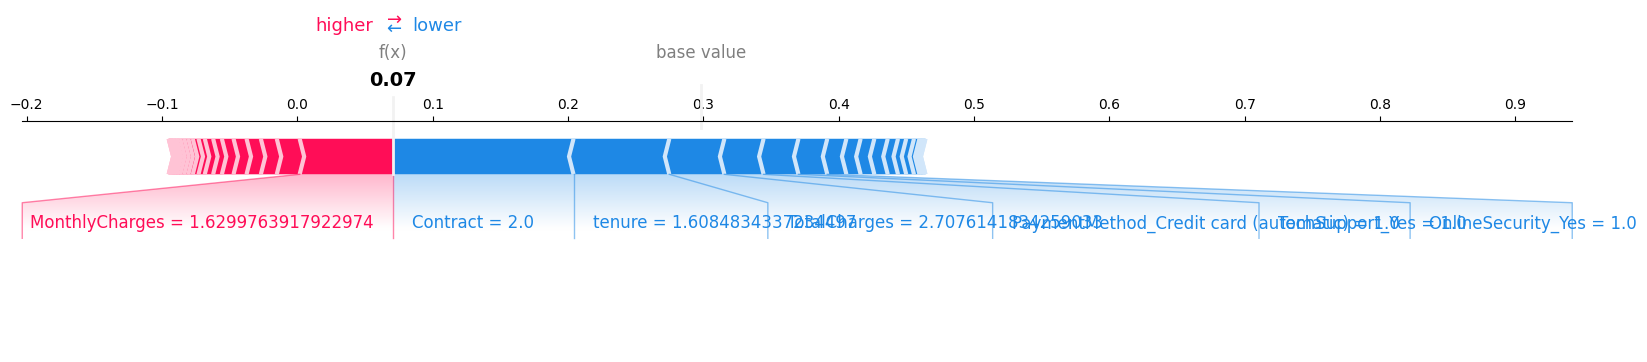

In [ ]:
# -------------------------
# 1. Background data
# -------------------------
np.random.seed(42)

background = X_train_processed[
    np.random.choice(X_train_processed.shape[0], 100, replace=False)
]

# Ensure float type
background = background.astype(np.float32)

# -------------------------
# 2. SHAP Explainer
# -------------------------
explainer = shap.DeepExplainer(model, background)

# -------------------------
# 3. Data to explain
# -------------------------
X_explain = X_test_processed[:200].astype(np.float32)

# -------------------------
# 4. Compute SHAP values
# -------------------------
shap_values = explainer.shap_values(X_explain)

# Handle list output (binary classification)
if isinstance(shap_values, list):
    shap_values = shap_values[0]

# Remove extra dimension if present
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 0]

# Final safety check
assert shap_values.shape == X_explain.shape

# -------------------------
# 5. FEATURE NAMES (FROM CSV + PREPROCESSOR)
# -------------------------

# Load raw column names from CSV
raw_columns = pd.read_csv(
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
).drop(columns=["customerID", "Churn"]).columns

# Ordinal feature
contract_feature = ["Contract"]

# One-hot encoded categorical features
cat_feature_names = (
    preprocessor
    .named_transformers_["cat"]
    .get_feature_names_out(categorical_cols)
    .tolist()
)

# Numerical features
num_feature_names = numerical_cols

# Final feature name list (MUST match ColumnTransformer order)
feature_names = (
    contract_feature +
    cat_feature_names +
    num_feature_names
)

# Convert to plain Python list (important!)
feature_names = list(feature_names)

# -------------------------
# 6. GLOBAL EXPLANATION
# -------------------------
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names
)

# -------------------------
# 7. FEATURE IMPORTANCE
# -------------------------
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    plot_type="bar"
)

# -------------------------
# 8. LOCAL EXPLANATION (NO ERROR)
# -------------------------
i = 0

shap.force_plot(
    float(explainer.expected_value[0]),
    shap_values[i].astype(float),
    X_explain[i].astype(float),
    feature_names=feature_names,
    matplotlib=True
)




##Autoencoder

In [ ]:
input_dim = X_train_processed.shape[1] # There are 38 features after processing, up from 19

encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(input_dim,)),
    tf.keras.layers.Dense(256,),
    tf.keras.layers.Dense(128,),
    tf.keras.layers.Dense(64,),
    tf.keras.layers.Dense(10,), # Reduce the processed features to a 10-dimensional representation
], name='encoder')

decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(10,)),
    tf.keras.layers.Dense(256, ),
    tf.keras.layers.Dense(128, ),
    tf.keras.layers.Dense(64, ),
    tf.keras.layers.Dense(input_dim),
], name='decoder')

autoencoder = tf.keras.models.Sequential([encoder, decoder],
                                         name='autoencoder')

autoencoder.compile(loss='binary_crossentropy', optimizer='adam')

autoencoder.fit(X_train_processed, X_train_processed, epochs=1000,
                callbacks=[tf.keras.callbacks.EarlyStopping(monitor='loss')],
                verbose=0)

In [ ]:
# Encoding
X_train_processed_ae = encoder.predict(X_train_processed)
X_test_processed_ae = encoder.predict(X_test_processed)
X_test_processed_ae.shape

177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


(1409, 10)

## The data with reduced features is now used on shallow learners to evaluate if it yields better results than before when all features were used

## Logistic Regression with Dimensionality Reduction

Test accuracy: 0.7693
              precision    recall  f1-score   support

          No       0.81      0.90      0.85      1035
         Yes       0.59      0.42      0.49       374

    accuracy                           0.77      1409
   macro avg       0.70      0.66      0.67      1409
weighted avg       0.75      0.77      0.76      1409



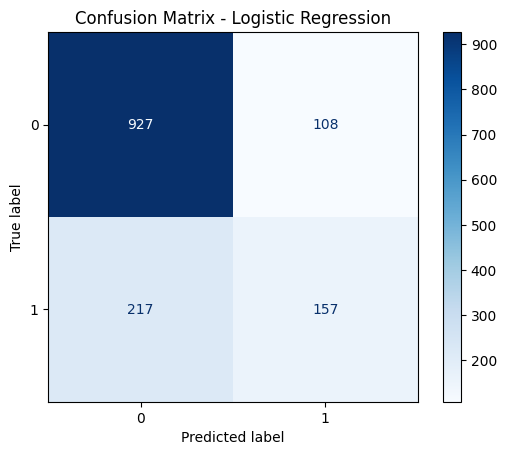

In [ ]:
log_reg = LogisticRegression(
    random_state=42,
    max_iter=1000,
    penalty='l2',
    C=0.01,
    solver='liblinear'
)

log_reg.fit(X_train_processed_ae, y_train)

# Predictions
y_pred = log_reg.predict(X_test_processed_ae)

# Accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

## Random Forest with Dimensionality Reduction

Test accuracy: 0.7786
              precision    recall  f1-score   support

          No       0.82      0.90      0.86      1035
         Yes       0.61      0.45      0.52       374

    accuracy                           0.78      1409
   macro avg       0.72      0.67      0.69      1409
weighted avg       0.76      0.78      0.77      1409



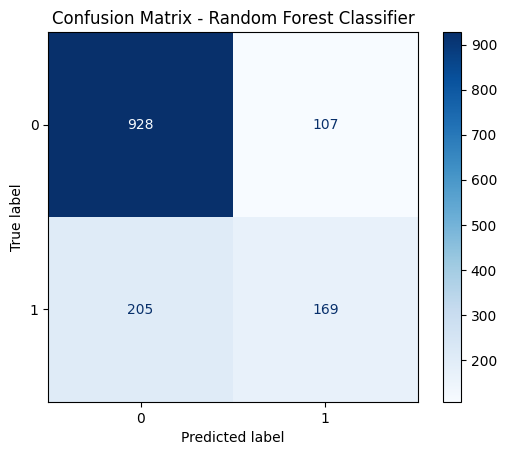

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42
)

rf.fit(X_train_processed_ae, y_train)

# Predictions
y_pred = rf.predict(X_test_processed_ae)

# Evaluation
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Random Forest Classifier")
plt.show()

## Gradient Boosting with Dimensionality Reduction

Test accuracy: 0.7708
              precision    recall  f1-score   support

           0       0.81      0.90      0.85      1035
           1       0.60      0.40      0.48       374

    accuracy                           0.77      1409
   macro avg       0.70      0.65      0.67      1409
weighted avg       0.75      0.77      0.75      1409

F2 score: 0.4298


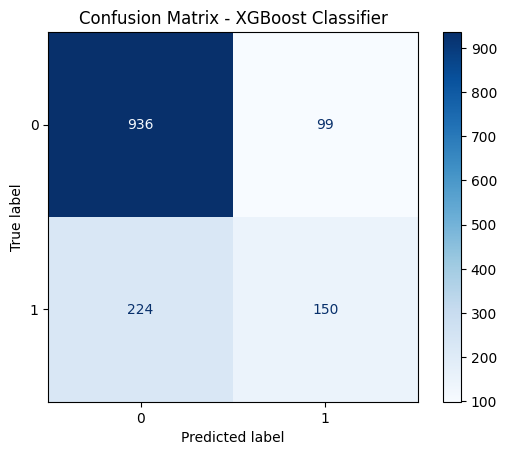

In [ ]:
xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    subsample=0.8,
    colsample_bytree=0.9,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train_processed_ae, y_train_encoded)

# Explicit prediction and accuracy calculation
y_pred_encoded = xgb.predict(X_test_processed_ae)
test_accuracy = accuracy_score(y_test_encoded, y_pred_encoded)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(y_test_encoded, y_pred_encoded))

f2 = fbeta_score(y_test_encoded, y_pred_encoded, beta=2, pos_label=1, average='binary')
print(f"F2 score: {f2:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test_encoded, y_pred_encoded)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - XGBoost Classifier")
plt.show()

## Ensemble with Dimensionality Reduction

Accuracy: 0.772888573456352
              precision    recall  f1-score   support

          No       0.81      0.90      0.85      1035
         Yes       0.60      0.43      0.50       374

    accuracy                           0.77      1409
   macro avg       0.71      0.66      0.68      1409
weighted avg       0.76      0.77      0.76      1409



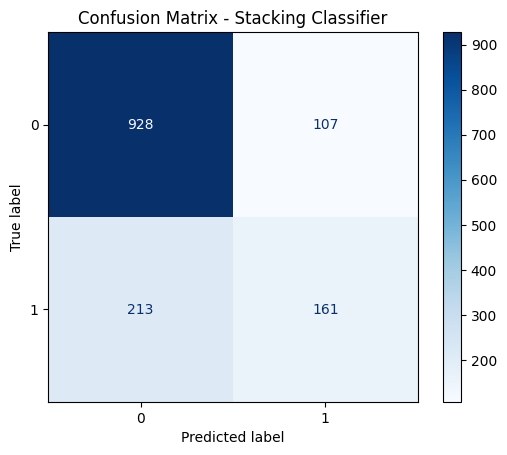

In [ ]:
# Base learners
base_learners = [
    ("lr", LogisticRegression(max_iter=1000, C= 0.01, penalty= 'l2', solver= 'liblinear', random_state=42)),
    ("rf", RandomForestClassifier(max_depth= 10, min_samples_leaf= 4, min_samples_split= 10, n_estimators= 200, random_state=42)),
    ("xgb", XGBClassifier(colsample_bytree= 0.8, learning_rate= 0.05, max_depth= 4, n_estimators= 100, subsample= 0.9, random_state=42))
]

# Meta Learner
meta_learner = XGBClassifier(colsample_bytree= 0.8, learning_rate= 0.05, max_depth= 4, n_estimators= 100, subsample= 0.9, random_state=42)

stacking_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

stacking_model.fit(X_train_processed_ae, y_train)

y_pred = stacking_model.predict(X_test_processed_ae)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Stacking Classifier")
plt.show()